In [10]:
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
!pip install torch-geometric==2.7.0
!pip install scikit-learn
!pip install imbalanced-learn
!pip install seaborn
!pip install joblib

Looking in indexes: https://download.pytorch.org/whl/cu118


In [11]:
import pandas as pd
import numpy as np
import json
import joblib

import seaborn as sns
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from imblearn.over_sampling import SMOTE

from torch_geometric.data import Data
from torch_geometric.nn import GATConv, GCNConv

In [12]:
df = pd.read_csv("processed.csv")

print(df.shape)

df.head()


(91830, 84)


,source_port,destination_port,protocol,flow_duration,total_fwd_packets,total_backward_packets,total_length_of_fwd_packets,fwd_packet_length_max,fwd_packet_length_min,fwd_packet_length_mean,...,idle_max,idle_min,newlabel,label,total_length_of_bwd_packets_long,total_length_of_bwd_packets_string,active_max_long,active_max_string,active_min_long,active_min_string
0,50956,443,6,278351,10,5,588,198,0,58.8,...,0.0,0.0,Normal,3,3832.0,NaN,0.0,NaN,0.0,NaN
1,22,8938,6,2,1,2,0,0,0,0.0,...,0.0,0.0,Normal,3,0.0,NaN,0.0,NaN,0.0,NaN
2,80,62184,6,24136457,1,5,6,6,6,6.0,...,24100000.0,24100000.0,Normal,3,30.0,NaN,42392.0,NaN,42392.0,NaN
3,63563,53,17,206,2,2,112,56,56,56.0,...,0.0,0.0,Normal,3,368.0,NaN,0.0,NaN,0.0,NaN
4,44123,53,17,198,2,2,66,33,33,33.0,...,0.0,0.0,Normal,3,164.0,NaN,0.0,NaN,0.0,NaN


In [13]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91830 entries, 0 to 91829
Data columns (total 84 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   source_port                         91830 non-null  int64  
 1   destination_port                    91830 non-null  int64  
 2   protocol                            91830 non-null  int64  
 3   flow_duration                       91830 non-null  int64  
 4   total_fwd_packets                   91830 non-null  int64  
 5   total_backward_packets              91830 non-null  int64  
 6   total_length_of_fwd_packets         91830 non-null  int64  
 7   fwd_packet_length_max               91830 non-null  int64  
 8   fwd_packet_length_min               91830 non-null  int64  
 9   fwd_packet_length_mean              91830 non-null  float64
 10  fwd_packet_length_std               91830 non-null  float64
 11  bwd_packet_length_max               91830

In [14]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 90


In [15]:
missing = df.isnull().sum()

missing[missing > 0].sort_values(
    ascending=False
)

,0
total_length_of_bwd_packets_string,91828
active_min_string,91821
active_max_string,91781
flow_bytess,77
active_max_long,49
active_min_long,9
total_length_of_bwd_packets_long,2


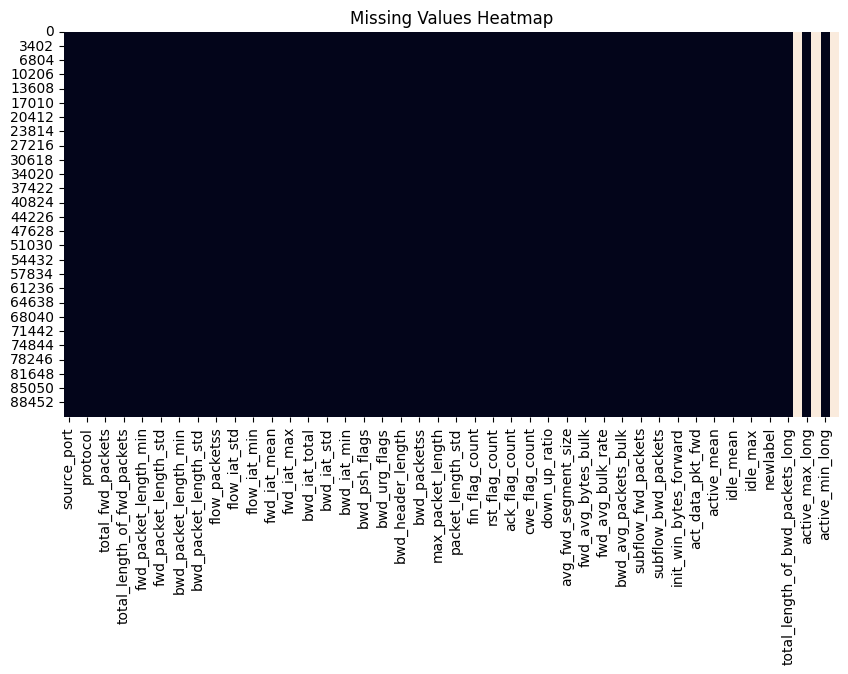

In [16]:
plt.figure(figsize=(10,5))

sns.heatmap(
    df.isnull(),
    cbar=False
)

plt.title(
    "Missing Values Heatmap"
)

plt.show()

In [17]:
label_names = {
    0:"Brute Force",
    1:"PortScan",
    2:"Botnet ARES",
    3:"Normal",
    4:"Infiltration",
    5:"Dos/DDos",
    6:"Web Attack"
}

df["attack_name"] = (
    df["label"]
    .astype(int)
    .map(label_names)
)

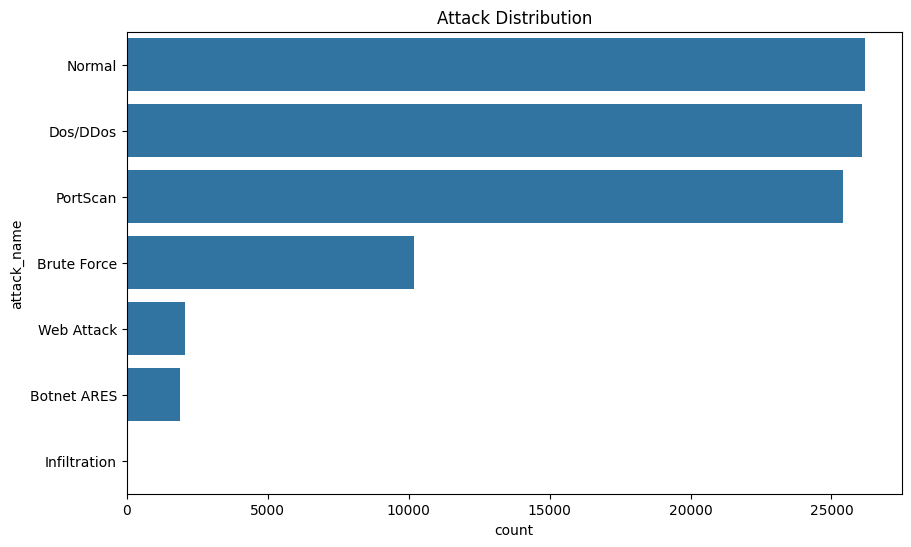

In [18]:
plt.figure(figsize=(10,6))

sns.countplot(
    y=df["attack_name"],
    order=df["attack_name"]
    .value_counts()
    .index
)

plt.title(
    "Attack Distribution"
)

plt.show()

In [19]:
df.describe()

,source_port,destination_port,protocol,flow_duration,total_fwd_packets,total_backward_packets,total_length_of_fwd_packets,fwd_packet_length_max,fwd_packet_length_min,fwd_packet_length_mean,...,idle_std,idle_max,idle_min,label,total_length_of_bwd_packets_long,total_length_of_bwd_packets_string,active_max_long,active_max_string,active_min_long,active_min_string
count,91830.000000,91830.000000,91830.000000,9.183000e+04,91830.000000,91830.000000,9.183000e+04,91830.000000,91830.000000,91830.000000,...,9.183000e+04,9.183000e+04,9.183000e+04,91830.000000,9.182800e+04,2.000000e+00,9.178100e+04,4.900000e+01,9.182100e+04,9.000000e+00
mean,45647.012088,5354.885353,7.330654,1.885866e+07,5.341163,5.399521,5.062310e+02,147.897343,7.542884,36.320629,...,6.792260e+05,1.567411e+07,1.464172e+07,2.728498,4.062632e+03,4.085000e+07,9.031476e+04,1.614490e+07,5.266891e+04,1.350000e+07
std,15736.621194,13659.207657,3.590268,3.641031e+07,76.599861,109.083690,1.541289e+04,559.087657,49.722169,147.366762,...,5.700434e+06,3.385888e+07,3.296638e+07,1.841623,5.153680e+04,1.548564e+07,6.575031e+05,6.123114e+06,4.953872e+05,4.874423e+06
min,0.000000,0.000000,0.000000,-1.000000e+00,1.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,2.990000e+07,0.000000e+00,1.000000e+07,0.000000e+00,1.000000e+07
25%,39583.000000,80.000000,6.000000,4.900000e+01,1.000000,1.000000,0.000000e+00,0.000000,0.000000,0.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,6.000000e+00,3.537500e+07,0.000000e+00,1.210000e+07,0.000000e+00,1.010000e+07
50%,50106.000000,80.000000,6.000000,8.975000e+02,2.000000,1.000000,1.400000e+01,6.000000,0.000000,6.000000,...,0.000000e+00,0.000000e+00,0.000000e+00,3.000000,6.000000e+00,4.085000e+07,0.000000e+00,1.360000e+07,0.000000e+00,1.210000e+07
75%,56262.750000,2035.000000,6.000000,9.057400e+06,6.000000,5.000000,2.800000e+02,195.000000,2.000000,45.500000,...,0.000000e+00,0.000000e+00,0.000000e+00,5.000000,2.745000e+03,4.632500e+07,0.000000e+00,1.970000e+07,0.000000e+00,1.310000e+07
max,65534.000000,65513.000000,17.000000,1.200000e+08,17739.000000,27020.000000,2.866110e+06,23360.000000,1983.000000,5940.857143,...,6.650000e+07,1.200000e+08,1.200000e+08,6.000000,7.649187e+06,5.180000e+07,9.780597e+06,4.160000e+07,9.780597e+06,2.530000e+07


In [20]:
feature_cols = [
    c
    for c in df.columns
    if c not in [
        "label",
        "newlabel",
        "attack_name"
    ]
]

X = df[feature_cols]

y = df["label"].astype(int)

In [21]:
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

X = X.clip(
    lower=-1000000,
    upper=1000000
)

X = X.fillna(
    X.mean()
)

print(
    "Any NaN:",
    X.isna().sum().sum()
)


Any NaN: 0


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (73464, 82)
Test: (18366, 82)


In [23]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

In [24]:
print(
    pd.Series(y_train)
    .value_counts()
)

label
3    20948
5    20853
1    20327
0     8161
6     1654
2     1498
4       23
Name: count, dtype: int64


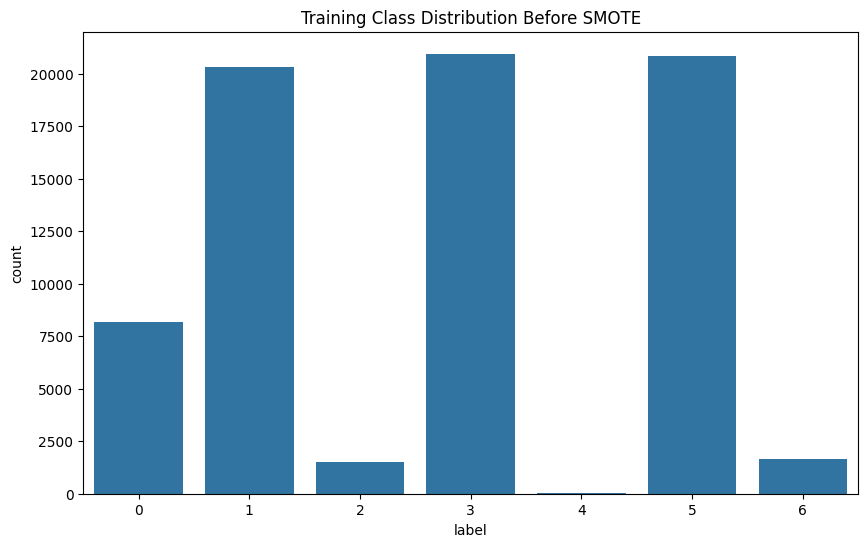

In [25]:
plt.figure(figsize=(10,6))

sns.countplot(x=y_train)

plt.title(
    "Training Class Distribution Before SMOTE"
)

plt.show()

In [26]:
print(X_train_scaled.shape)
print(y_train.shape)
print(pd.Series(y_train).value_counts())

(73464, 82)
(73464,)
label
3    20948
5    20853
1    20327
0     8161
6     1654
2     1498
4       23
Name: count, dtype: int64


In [27]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42,
    k_neighbors=1
)

X_train_bal, y_train_bal = smote.fit_resample(
    X_train_scaled,
    y_train
)

print(X_train_bal.shape)
print(pd.Series(y_train_bal).value_counts())

(146636, 82)
label
5    20948
1    20948
3    20948
0    20948
2    20948
6    20948
4    20948
Name: count, dtype: int64


In [28]:
pd.Series(y_train).value_counts()

,count
label,
3,20948
5,20853
1,20327
0,8161
6,1654
2,1498
4,23


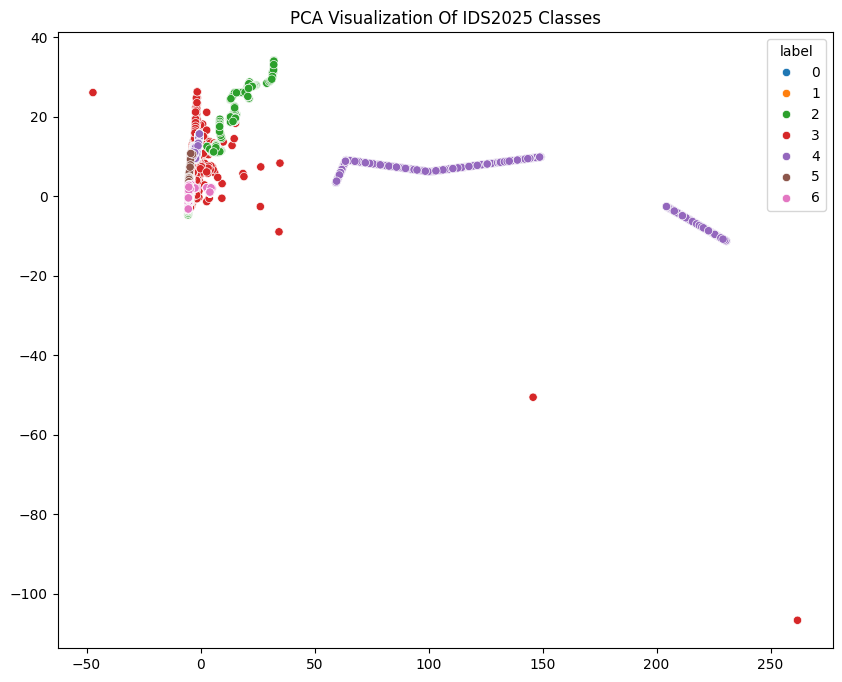

In [29]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(
    X_train_bal
)

plt.figure(figsize=(10,8))

sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=y_train_bal,
    palette="tab10"
)

plt.title(
    "PCA Visualization Of IDS2025 Classes"
)

plt.show()

In [30]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(
    X_train_bal,
    y_train_bal
)

RandomForestClassifier(random_state=42)

In [31]:
importance = pd.DataFrame(
    {
        "Feature": feature_cols,
        "Importance": rf.feature_importances_
    }
)

importance = importance.sort_values(
    "Importance",
    ascending=False
)

importance.head(20)

,Feature,Importance
1,destination_port,0.137775
67,init_win_bytes_backward,0.066182
66,init_win_bytes_forward,0.037979
13,bwd_packet_length_mean,0.030501
6,total_length_of_fwd_packets,0.030220
7,fwd_packet_length_max,0.027796
69,min_seg_size_forward,0.026164
38,bwd_packetss,0.025398
41,packet_length_mean,0.025012
54,avg_fwd_segment_size,0.024429


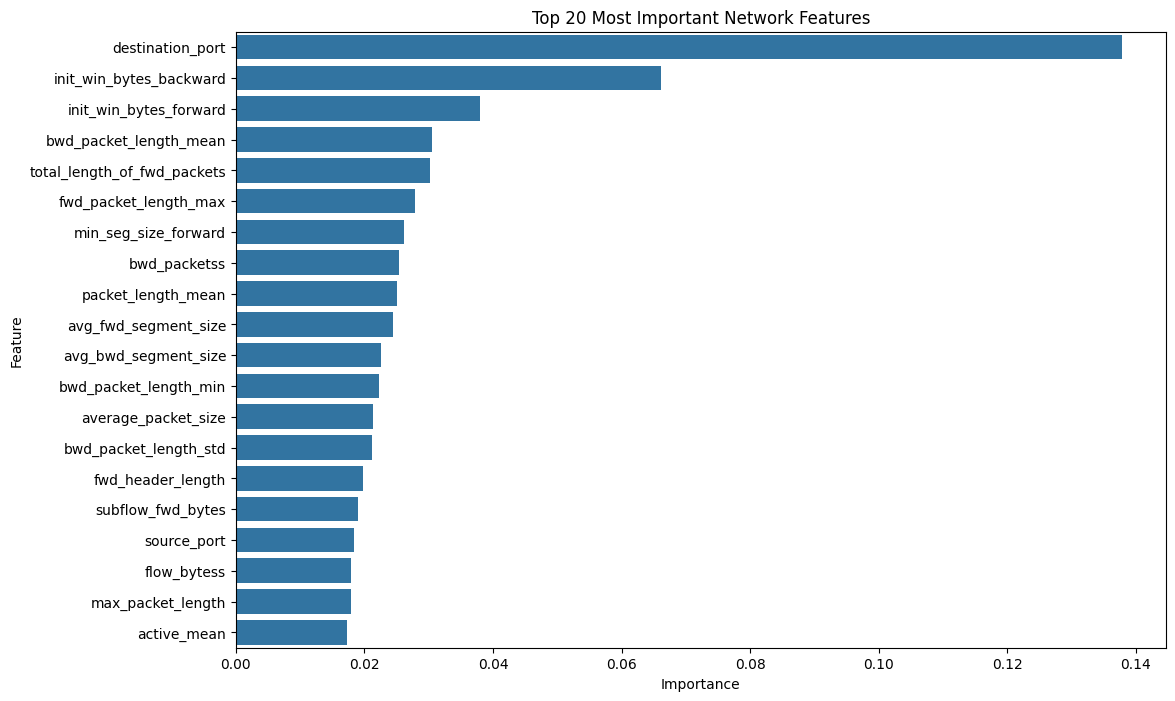

In [32]:
plt.figure(figsize=(12,8))

sns.barplot(
    data=importance.head(20),
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 20 Most Important Network Features"
)

plt.show()

In [33]:
from sklearn.neighbors import NearestNeighbors

k = 10

nbrs_train = NearestNeighbors(
    n_neighbors=k+1
)

nbrs_train.fit(
    X_train_bal
)

distances_train, indices_train = nbrs_train.kneighbors(
    X_train_bal
)

edge_index_train = []

for i in range(len(X_train_bal)):

    for j in indices_train[i]:

        if i != j:

            edge_index_train.append(
                [i,j]
            )

edge_index_train = torch.tensor(
    edge_index_train,
    dtype=torch.long
).t().contiguous()

print(
    "Train Graph:",
    edge_index_train.shape
)

Train Graph: torch.Size([2, 1466360])


In [34]:
nbrs_test = NearestNeighbors(
    n_neighbors=k+1
)

nbrs_test.fit(
    X_test_scaled
)

distances_test, indices_test = nbrs_test.kneighbors(
    X_test_scaled
)

edge_index_test = []

for i in range(len(X_test_scaled)):

    for j in indices_test[i]:

        if i != j:

            edge_index_test.append(
                [i,j]
            )

edge_index_test = torch.tensor(
    edge_index_test,
    dtype=torch.long
).t().contiguous()

print(
    "Test Graph:",
    edge_index_test.shape
)

Test Graph: torch.Size([2, 183660])


In [35]:
from torch_geometric.data import Data

train_data = Data(
    x=torch.tensor(
        X_train_bal,
        dtype=torch.float
    ),
    y=torch.tensor(
        y_train_bal,
        dtype=torch.long
    ),
    edge_index=edge_index_train
)

test_data = Data(
    x=torch.tensor(
        X_test_scaled,
        dtype=torch.float
    ),
    y=torch.tensor(
        y_test.values,
        dtype=torch.long
    ),
    edge_index=edge_index_test
)

print(train_data)
print(test_data)

Data(x=[146636, 82], edge_index=[2, 1466360], y=[146636])
Data(x=[18366, 82], edge_index=[2, 183660], y=[18366])


In [36]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

train_data = train_data.to(device)

test_data = test_data.to(device)

print(device)

cuda


In [37]:
import torch.nn as nn
from torch_geometric.nn import GATConv

class GATNet(nn.Module):

    def __init__(
        self,
        in_channels,
        hidden_channels,
        out_channels
    ):

        super().__init__()

        self.gat1 = GATConv(
            in_channels,
            hidden_channels,
            heads=4
        )

        self.gat2 = GATConv(
            hidden_channels * 4,
            out_channels,
            heads=1
        )

    def forward(
        self,
        x,
        edge_index
    ):

        x = torch.relu(
            self.gat1(
                x,
                edge_index
            )
        )

        x = self.gat2(
            x,
            edge_index
        )

        return x


In [38]:
num_classes = len(
    np.unique(
        y_train_bal
    )
)

gat = GATNet(
    in_channels=train_data.num_node_features,
    hidden_channels=64,
    out_channels=num_classes
).to(device)

In [39]:
optimizer = torch.optim.Adam(
    gat.parameters(),
    lr=0.001
)

loss_fn = nn.CrossEntropyLoss()

losses = []

In [40]:
for epoch in range(50):

    gat.train()

    optimizer.zero_grad()

    out = gat(
        train_data.x,
        train_data.edge_index
    )

    loss = loss_fn(
        out,
        train_data.y
    )

    loss.backward()

    optimizer.step()

    losses.append(
        loss.item()
    )

    if epoch % 10 == 0:

        print(
            f"Epoch {epoch} Loss={loss.item():.4f}"
        )

Epoch 0 Loss=2.3658
Epoch 10 Loss=1.0073
Epoch 20 Loss=0.6774
Epoch 30 Loss=0.5209
Epoch 40 Loss=0.4285


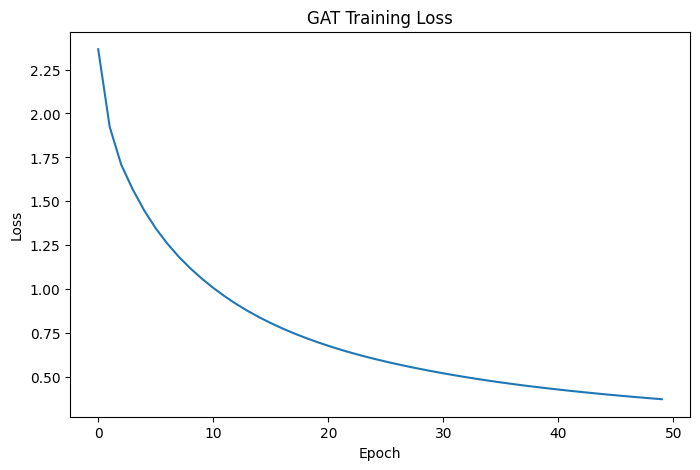

In [41]:
plt.figure(figsize=(8,5))

plt.plot(losses)

plt.title(
    "GAT Training Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.show()

In [42]:
gat.eval()

with torch.no_grad():

    out = gat(
        test_data.x,
        test_data.edge_index
    )

pred_val = (
    out.argmax(dim=1)
    .cpu()
)

y_val = (
    test_data.y
    .cpu()
)

In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

gat_acc = accuracy_score(
    y_val,
    pred_val
)

gat_precision = precision_score(
    y_val,
    pred_val,
    average="weighted"
)

gat_recall = recall_score(
    y_val,
    pred_val,
    average="weighted"
)

gat_f1 = f1_score(
    y_val,
    pred_val,
    average="weighted"
)

print("Accuracy:", gat_acc)
print("Precision:", gat_precision)
print("Recall:", gat_recall)
print("F1:", gat_f1)

Accuracy: 0.8951323097027115
Precision: 0.9184188449840323
Recall: 0.8951323097027115
F1: 0.8982553206804161


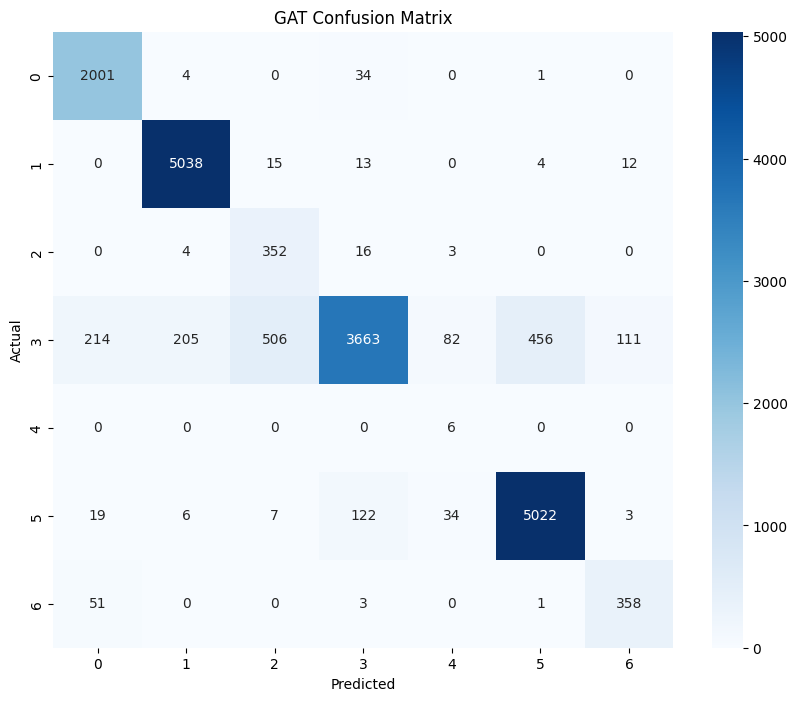

In [44]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_val,
    pred_val
)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(
    "GAT Confusion Matrix"
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.show()

In [45]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_val,
        pred_val,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.8757    0.9809    0.9253      2040
           1     0.9583    0.9913    0.9746      5082
           2     0.4000    0.9387    0.5610       375
           3     0.9512    0.6994    0.8061      5237
           4     0.0480    1.0000    0.0916         6
           5     0.9158    0.9634    0.9390      5213
           6     0.7397    0.8668    0.7982       413

    accuracy                         0.8951     18366
   macro avg     0.6984    0.9201    0.7280     18366
weighted avg     0.9184    0.8951    0.8983     18366



In [46]:
report = classification_report(
    y_val,
    pred_val,
    output_dict=True
)

report_df = pd.DataFrame(
    report
).transpose()

report_df

,precision,recall,f1-score,support
0,0.875711,0.980882,0.925318,2040.000000
1,0.958341,0.991342,0.974562,5082.000000
2,0.400000,0.938667,0.560956,375.000000
3,0.951182,0.699446,0.806118,5237.000000
4,0.048000,1.000000,0.091603,6.000000
5,0.915755,0.963361,0.938955,5213.000000
6,0.739669,0.866828,0.798216,413.000000
accuracy,0.895132,0.895132,0.895132,0.895132
macro avg,0.698380,0.920075,0.727961,18366.000000
weighted avg,0.918419,0.895132,0.898255,18366.000000


In [47]:
attack_names = {
    "0":"Brute Force",
    "1":"PortScan",
    "2":"Botnet ARES",
    "3":"Normal",
    "4":"Infiltration",
    "5":"Dos/DDos",
    "6":"Web Attack"
}

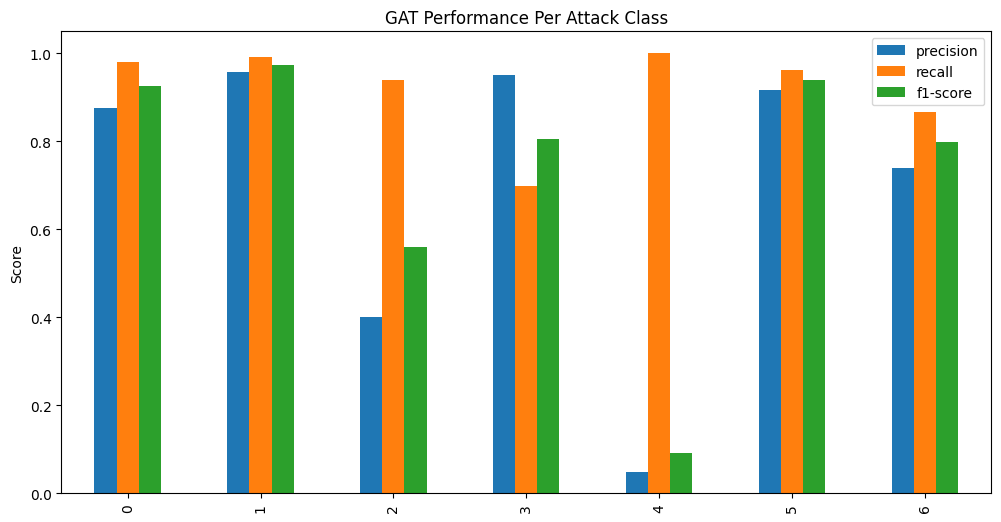

In [48]:
classes = report_df.index[:-3]

metrics_df = report_df.loc[
    classes,
    [
        "precision",
        "recall",
        "f1-score"
    ]
]

metrics_df.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title(
    "GAT Performance Per Attack Class"
)

plt.ylabel(
    "Score"
)

plt.ylim(0,1.05)

plt.show()

In [49]:
from torch_geometric.nn import GCNConv

class GCNNet(nn.Module):

    def __init__(
        self,
        in_channels,
        hidden_channels,
        out_channels
    ):

        super().__init__()

        self.conv1 = GCNConv(
            in_channels,
            hidden_channels
        )

        self.conv2 = GCNConv(
            hidden_channels,
            out_channels
        )

    def forward(
        self,
        x,
        edge_index
    ):

        x = torch.relu(
            self.conv1(
                x,
                edge_index
            )
        )

        x = self.conv2(
            x,
            edge_index
        )

        return x


In [50]:
gcn = GCNNet(
    train_data.num_node_features,
    64,
    num_classes
).to(device)

In [51]:
optimizer = torch.optim.Adam(
    gcn.parameters(),
    lr=0.001
)

loss_fn = nn.CrossEntropyLoss()


In [52]:
gcn_losses = []

for epoch in range(50):

    gcn.train()

    optimizer.zero_grad()

    out = gcn(
        train_data.x,
        train_data.edge_index
    )

    loss = loss_fn(
        out,
        train_data.y
    )

    loss.backward()

    optimizer.step()

    gcn_losses.append(
        loss.item()
    )

    if epoch % 10 == 0:

        print(
            f"Epoch {epoch} Loss={loss.item():.4f}"
        )


Epoch 0 Loss=2.0905
Epoch 10 Loss=1.4571
Epoch 20 Loss=1.0824
Epoch 30 Loss=0.8638
Epoch 40 Loss=0.7238


In [53]:
gcn.eval()

with torch.no_grad():

    out = gcn(
        test_data.x,
        test_data.edge_index
    )

gcn_preds = (
    out.argmax(
        dim=1
    )
    .cpu()
)

pred_val_gcn = gcn_preds

In [54]:
gcn_acc = accuracy_score(
    y_val,
    pred_val_gcn
)

gcn_precision = precision_score(
    y_val,
    pred_val_gcn,
    average="weighted"
)

gcn_recall = recall_score(
    y_val,
    pred_val_gcn,
    average="weighted"
)

gcn_f1 = f1_score(
    y_val,
    pred_val_gcn,
    average="weighted"
)

print("Accuracy:", gcn_acc)
print("Precision:", gcn_precision)
print("Recall:", gcn_recall)
print("F1:", gcn_f1)

Accuracy: 0.8019165849940106
Precision: 0.8973112173806885
Recall: 0.8019165849940106
F1: 0.8306357440500736


In [55]:
class GTLayer(nn.Module):

    def __init__(
        self,
        num_edge_types
    ):
        super().__init__()

        self.weight = nn.Parameter(
            torch.randn(
                num_edge_types
            )
        )

    def forward(
        self,
        adjs
    ):
        A = 0

        for i, adj in enumerate(adjs):

            A = (
                A +
                self.weight[i] * adj
            )

        return A

In [56]:
class GTNNet(nn.Module):

    def __init__(
        self,
        num_edge_types,
        in_channels,
        hidden_channels,
        out_channels
    ):

        super().__init__()

        self.layer1 = GTLayer(
            num_edge_types
        )

        self.fc1 = nn.Linear(
            in_channels,
            hidden_channels
        )

        self.fc2 = nn.Linear(
            hidden_channels,
            out_channels
        )

    def forward(
        self,
        x,
        adjs
    ):

        A = self.layer1(
            adjs
        )

        x = torch.relu(
            self.fc1(x)
        )

        x = self.fc2(x)

        return x

In [57]:
adjs = []

for _ in range(3):

    A = torch.tensor(
        [[0.,1.],
         [1.,0.]],
         dtype=torch.float
    ).to(device)

    adjs.append(A)

print(
    "Adjacency Matrices:",
    len(adjs)
)

Adjacency Matrices: 3


In [58]:
gtn = GTNNet(
    len(adjs),
    train_data.num_node_features,
    64,
    num_classes
).to(device)

In [59]:
optimizer = torch.optim.Adam(
    gtn.parameters(),
    lr=0.001
)

loss_fn = nn.CrossEntropyLoss()

gtn_losses = []

In [60]:
for epoch in range(50):

    gtn.train()

    optimizer.zero_grad()

    out = gtn(
        train_data.x,
        adjs
    )

    loss = loss_fn(
        out,
        train_data.y
    )

    loss.backward()

    optimizer.step()

    gtn_losses.append(
        loss.item()
    )

    if epoch % 10 == 0:

        print(
            f"Epoch {epoch} Loss={loss.item():.4f}"
        )

Epoch 0 Loss=2.1492
Epoch 10 Loss=1.6553
Epoch 20 Loss=1.3969
Epoch 30 Loss=1.1817
Epoch 40 Loss=0.9980


In [61]:
gtn.eval()

with torch.no_grad():

    out = gtn(
        test_data.x,
        adjs
    )

gtn_preds = (
    out.argmax(
        dim=1
    )
    .cpu()
)

pred_val_gtn = gtn_preds

In [62]:
gtn_acc = accuracy_score(
    y_val,
    pred_val_gtn
)

gtn_precision = precision_score(
    y_val,
    pred_val_gtn,
    average="weighted"
)

gtn_recall = recall_score(
    y_val,
    pred_val_gtn,
    average="weighted"
)

gtn_f1 = f1_score(
    y_val,
    pred_val_gtn,
    average="weighted"
)

print("Accuracy:", gtn_acc)
print("Precision:", gtn_precision)
print("Recall:", gtn_recall)
print("F1:", gtn_f1)

Accuracy: 0.7387563976913862
Precision: 0.8517262469565666
Recall: 0.7387563976913862
F1: 0.754197009783327


In [63]:
comparison = pd.DataFrame({
    "Model":["GAT","GCN","GTN"],
    "Accuracy":[gat_acc,gcn_acc,gtn_acc],
    "Precision":[gat_precision,gcn_precision,gtn_precision],
    "Recall":[gat_recall,gcn_recall,gtn_recall],
    "F1":[gat_f1,gcn_f1,gtn_f1]
})

comparison

,Model,Accuracy,Precision,Recall,F1
0,GAT,0.895132,0.918419,0.895132,0.898255
1,GCN,0.801917,0.897311,0.801917,0.830636
2,GTN,0.738756,0.851726,0.738756,0.754197


<Figure size 1000x600 with 0 Axes>

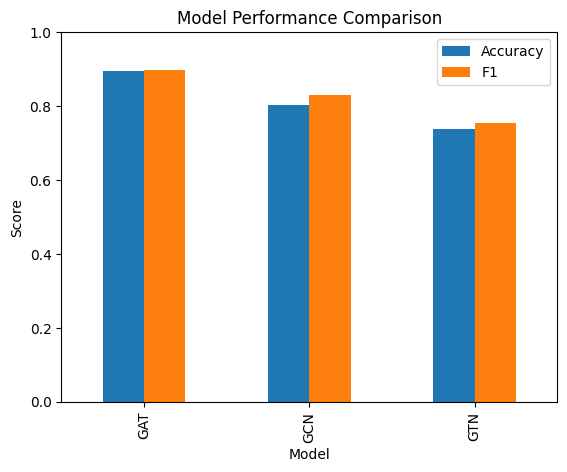

In [64]:
plt.figure(figsize=(10,6))

comparison.set_index(
    "Model"
)[["Accuracy","F1"]].plot(
    kind="bar"
)

plt.title(
    "Model Performance Comparison"
)

plt.ylabel("Score")

plt.ylim(0,1)

plt.show()

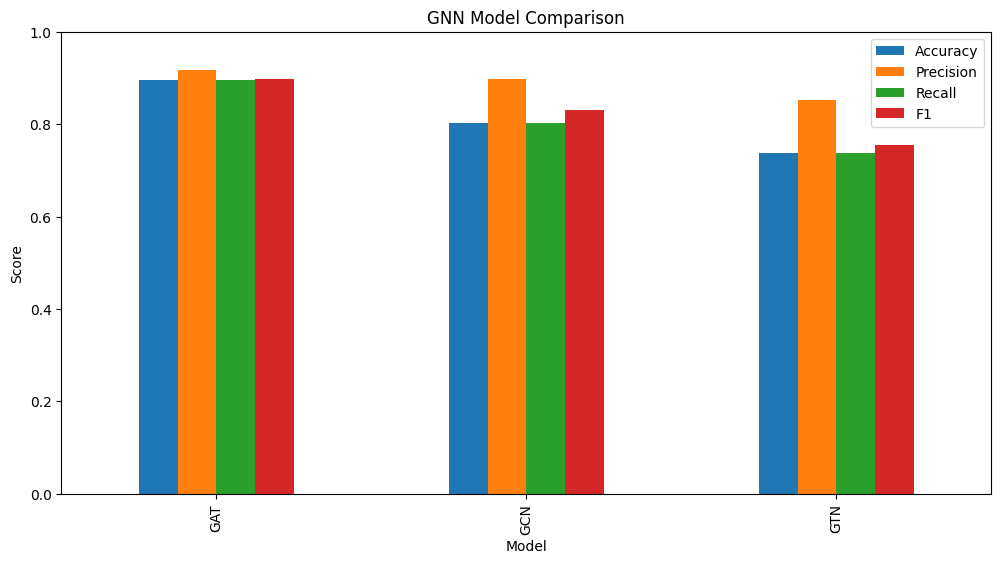

In [65]:
comparison.set_index(
    "Model"
).plot(
    kind="bar",
    figsize=(12,6)
)

plt.title(
    "GNN Model Comparison"
)

plt.ylabel("Score")

plt.ylim(0,1)

plt.show()


In [66]:
print(
    classification_report(
        y_val,
        pred_val,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.8757    0.9809    0.9253      2040
           1     0.9583    0.9913    0.9746      5082
           2     0.4000    0.9387    0.5610       375
           3     0.9512    0.6994    0.8061      5237
           4     0.0480    1.0000    0.0916         6
           5     0.9158    0.9634    0.9390      5213
           6     0.7397    0.8668    0.7982       413

    accuracy                         0.8951     18366
   macro avg     0.6984    0.9201    0.7280     18366
weighted avg     0.9184    0.8951    0.8983     18366



In [67]:
print("="*60)
print("GAT 5-FOLD CROSS VALIDATION")
print("="*60)

from sklearn.model_selection import StratifiedKFold

cv_accuracy = []
cv_f1 = []

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold = 1

for train_idx, test_idx in skf.split(X, y):

    print(f"\nFold {fold}")

    X_train_cv = X.iloc[train_idx]
    X_test_cv = X.iloc[test_idx]

    y_train_cv = y.iloc[train_idx]
    y_test_cv = y.iloc[test_idx]

    scaler_cv = StandardScaler()

    X_train_cv = scaler_cv.fit_transform(
        X_train_cv
    )

    X_test_cv = scaler_cv.transform(
        X_test_cv
    )

    smote = SMOTE(
        random_state=42,
        k_neighbors=1
    )

    X_train_cv, y_train_cv = smote.fit_resample(
        X_train_cv,
        y_train_cv
    )

    nbrs_train = NearestNeighbors(
        n_neighbors=11
    )

    nbrs_train.fit(
        X_train_cv
    )

    distances, indices = nbrs_train.kneighbors(
        X_train_cv
    )

    edge_train = []

    for i in range(len(X_train_cv)):

        for j in indices[i]:

            if i != j:

                edge_train.append(
                    [i,j]
                )

    edge_train = torch.tensor(
        edge_train,
        dtype=torch.long
    ).t().contiguous()

    nbrs_test = NearestNeighbors(
        n_neighbors=11
    )

    nbrs_test.fit(
        X_test_cv
    )

    distances, indices = nbrs_test.kneighbors(
        X_test_cv
    )

    edge_test = []

    for i in range(len(X_test_cv)):

        for j in indices[i]:

            if i != j:

                edge_test.append(
                    [i,j]
                )

    edge_test = torch.tensor(
        edge_test,
        dtype=torch.long
    ).t().contiguous()

    train_graph = Data(
        x=torch.tensor(
            X_train_cv,
            dtype=torch.float
        ),
        y=torch.tensor(
            y_train_cv,
            dtype=torch.long
        ),
        edge_index=edge_train
    )

    test_graph = Data(
        x=torch.tensor(
            X_test_cv,
            dtype=torch.float
        ),
        y=torch.tensor(
            y_test_cv.values,
            dtype=torch.long
        ),
        edge_index=edge_test
    )

    train_graph = train_graph.to(device)
    test_graph = test_graph.to(device)

    cv_model = GATNet(
        in_channels=train_graph.num_node_features,
        hidden_channels=64,
        out_channels=num_classes
    ).to(device)

    optimizer = torch.optim.Adam(
        cv_model.parameters(),
        lr=0.001
    )

    loss_fn = nn.CrossEntropyLoss()

    for epoch in range(20):

        cv_model.train()

        optimizer.zero_grad()

        out = cv_model(
            train_graph.x,
            train_graph.edge_index
        )

        loss = loss_fn(
            out,
            train_graph.y
        )

        loss.backward()

        optimizer.step()

    cv_model.eval()

    with torch.no_grad():

        out = cv_model(
            test_graph.x,
            test_graph.edge_index
        )

    preds = (
        out.argmax(dim=1)
        .cpu()
    )

    y_true = (
        test_graph.y
        .cpu()
    )

    acc = accuracy_score(
        y_true,
        preds
    )

    f1 = f1_score(
        y_true,
        preds,
        average="weighted"
    )

    cv_accuracy.append(acc)
    cv_f1.append(f1)

    print(
        f"Accuracy: {acc:.4f}"
    )

    print(
        f"F1: {f1:.4f}"
    )

    fold += 1

print("\n"+"="*60)
print("FINAL CROSS VALIDATION RESULTS")
print("="*60)

print(
    "Fold Accuracies:",
    cv_accuracy
)

print(
    "Mean Accuracy:",
    np.mean(cv_accuracy)
)

print(
    "Std Accuracy:",
    np.std(cv_accuracy)
)

print(
    "Mean F1:",
    np.mean(cv_f1)
)

print(
    "Std F1:",
    np.std(cv_f1)
)

GAT 5-FOLD CROSS VALIDATION

Fold 1
Accuracy: 0.8190
F1: 0.8256

Fold 2
Accuracy: 0.7997
F1: 0.8280

Fold 3
Accuracy: 0.7983
F1: 0.8051

Fold 4
Accuracy: 0.7824
F1: 0.8016

Fold 5
Accuracy: 0.7471
F1: 0.7662

FINAL CROSS VALIDATION RESULTS
Fold Accuracies: [0.8190133943155832, 0.7997386475008167, 0.7982685396929108, 0.7824240444299249, 0.747141457040183]
Mean Accuracy: 0.7893172165958837
Std Accuracy: 0.024070338157423005
Mean F1: 0.8053145947041387
Std F1: 0.0222270263941679


In [68]:
torch.save(
    gat.state_dict(),
    "gat_model_balanced.pth"
)

In [69]:
import joblib

joblib.dump(
    scaler,
    "scaler.pkl"
)

['scaler.pkl']

In [70]:
import json

with open(
    "features.json",
    "w"
) as f:

    json.dump(
        feature_cols,
        f
    )

In [71]:
label_map = {
    0:"Brute Force",
    1:"PortScan",
    2:"Botnet ARES",
    3:"Normal",
    4:"Infiltration",
    5:"Dos/DDos",
    6:"Web Attack"
}

with open(
    "label_map.json",
    "w"
) as f:

    json.dump(
        label_map,
        f
    )

In [72]:
print(len(feature_cols))
feature_cols[:20]

82


['source_port',
 'destination_port',
 'protocol',
 'flow_duration',
 'total_fwd_packets',
 'total_backward_packets',
 'total_length_of_fwd_packets',
 'fwd_packet_length_max',
 'fwd_packet_length_min',
 'fwd_packet_length_mean',
 'fwd_packet_length_std',
 'bwd_packet_length_max',
 'bwd_packet_length_min',
 'bwd_packet_length_mean',
 'bwd_packet_length_std',
 'flow_bytess',
 'flow_packetss',
 'flow_iat_mean',
 'flow_iat_std',
 'flow_iat_max']

In [75]:
import json

with open(
    "cleaned_20261106_151524_688aa195-c21d-43a9-be28-211f0d2e054e.json"
) as f:

    sample = json.load(f)

print(
    sample["newlabel"]
)

Normal


In [76]:
row = []

for feature in feature_cols:

    value = sample.get(
        feature,
        0
    )

    try:
        value = float(value)

    except:
        value = 0

    row.append(value)

X_sample = np.array([row])

X_scaled = scaler.transform(
    X_sample
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [77]:
x = torch.tensor(
    X_scaled,
    dtype=torch.float
)

edge_index = torch.tensor(
    [[0],
     [0]],
    dtype=torch.long
).to(device)

In [78]:
gat.eval()

with torch.no_grad():

    out = gat(
        x.to(device),
        edge_index
    )

pred = out.argmax(
    dim=1
).item()

print(
    "Actual:",
    sample["newlabel"]
)

print(
    "Predicted:",
    label_map[pred]
)

Actual: Normal
Predicted: Normal


In [79]:
import torch

state = torch.load(
    "gat_model_balanced.pth",
    map_location="cpu"
)

first_key = list(state.keys())[0]

print(first_key)

print(
    state[first_key].flatten()[:10]
)

gat1.att_src
tensor([ 0.1087,  0.1308, -0.2013,  0.2208, -0.2285,  0.1763,  0.0573,  0.1177,
         0.1628,  0.1496])
